# Projeto 02 - Inteligência Artificial (2026)
## Notebook 04: Mineração de Padrões Frequentes e Regras de Associação (*Apriori from Scratch*)

---

### Identificação do Grupo e Alunos
* **Grupo:** G51233
* **Aluno 1:** 51233 - Lucas Lima Magalhães *(Contribuição: 100%)*

---

### Contexto do Trabalho e Objetivos de Negócio
A descoberta de regras de associação visa identificar dependências probabilísticas, coocorrências e associações implícitas do tipo **Se [Antecedente] $\implies$ Então [Consequente]**.
* **Problema de Negócio:** Mapear regras que caracterizam o perfil imobiliário da Califórnia (Housing) e cruzar condições de renda, localização geográfica, idade do imóvel e faixas de preço para orientar decisões de crédito e investimento.
* **Métricas Formais:**
  - **Suporte ($Supp$):** Frequência relativa conjunta $P(A \cap B)$.
  - **Confiança ($Conf$):** Certeza condicional da regra $P(B \mid A) = \frac{Supp(A \cup B)}{Supp(A)}$.
  - **Lift ($Lift$):** Força da associação além da independência causal $\frac{P(B \mid A)}{P(B)} = \frac{Supp(A \cup B)}{Supp(A) \times Supp(B)}$. ($Lift > 1$ indica correlação positiva).
  - **Alavancagem ($Leverage$) e Convicção ($Conviction$):** Medidas de desvio da independência estatística e dependência direcional.

> **Regra de Conformidade Estrita:** O algoritmo Apriori e a geração de regras de associação foram implementados **100% from scratch** em Python e Pandas (`src.apriori`), sem utilização de bibliotecas proibidas (`mlxtend`, `sklearn`, etc.).


In [1]:
# Importações estritamente em Python puro, NumPy, Pandas e Módulos Locais (sem mlxtend / sklearn)
import os
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

# Módulos locais desenvolvidos na FASE 1
sys.path.append(os.path.abspath('..'))
from src.apriori import apriori, association_rules
from src.preprocessing import impute_missing

print("Módulo Apriori from scratch importado com sucesso!")

Módulo Apriori from scratch importado com sucesso!


## 1. Preparação dos Dados: Discretização e Matriz Transacional

Algoritmos baseados no princípio Apriori operam sobre itens discretos e transações binárias. Para aplicar o método a variáveis contínuas, realizamos uma discretização semântica baseada em quantis e regras de negócio:
- `median_income`: `Renda_Baixa`, `Renda_Media`, `Renda_Alta`, `Renda_MuitoAlta`
- `median_house_value`: `Imovel_Economico`, `Imovel_Medio`, `Imovel_Elevado`, `Imovel_Luxo`
- `housing_median_age`: `Imovel_Novo`, `Imovel_Maduro`, `Imovel_Historico`
- `ocean_proximity`: `Local_{Categoria}`


In [2]:
# 1. Carregamento dos dados
data_path = os.path.join('data', 'housing.csv')
df_raw = pd.read_csv(data_path)
df_clean = impute_missing(df_raw, strategy='median')

# 2. Discretização baseada em quantis para balanceamento semântico
df_trans = pd.DataFrame()

# Renda Mediana (4 faixas)
df_trans['Renda'] = pd.qcut(
    df_clean['median_income'], q=4, 
    labels=['Renda_Baixa', 'Renda_Media', 'Renda_Alta', 'Renda_MuitoAlta']
)

# Valor Mediano do Imóvel (4 faixas)
df_trans['Preco_Imovel'] = pd.qcut(
    df_clean['median_house_value'], q=4,
    labels=['Imovel_Economico', 'Imovel_Medio', 'Imovel_Elevado', 'Imovel_Luxo']
)

# Idade do Imóvel (3 faixas)
df_trans['Idade_Imovel'] = pd.qcut(
    df_clean['housing_median_age'], q=3,
    labels=['Imovel_Novo', 'Imovel_Maduro', 'Imovel_Historico']
)

# Localização geográfica
df_trans['Localizacao'] = 'Local_' + df_clean['ocean_proximity'].str.replace(' ', '_').str.replace('<', 'Menos_')

# 3. Transformação em formato transacional One-Hot (booleano)
df_onehot = pd.get_dummies(df_trans, dtype=bool)

print(f"Matriz transacional binária criada com {df_onehot.shape[0]} transações e {df_onehot.shape[1]} itens:")
display(df_onehot.head(4))

Matriz transacional binária criada com 20640 transações e 16 itens:


,Renda_Renda_Baixa,Renda_Renda_Media,Renda_Renda_Alta,Renda_Renda_MuitoAlta,Preco_Imovel_Imovel_Economico,Preco_Imovel_Imovel_Medio,Preco_Imovel_Imovel_Elevado,Preco_Imovel_Imovel_Luxo,Idade_Imovel_Imovel_Novo,Idade_Imovel_Imovel_Maduro,Idade_Imovel_Imovel_Historico,Localizacao_Local_INLAND,Localizacao_Local_ISLAND,Localizacao_Local_Menos_1H_OCEAN,Localizacao_Local_NEAR_BAY,Localizacao_Local_NEAR_OCEAN
0,False,False,False,True,False,False,False,True,False,False,True,False,False,False,True,False
1,False,False,False,True,False,False,False,True,True,False,False,False,False,False,True,False
2,False,False,False,True,False,False,False,True,False,False,True,False,False,False,True,False
3,False,False,False,True,False,False,False,True,False,False,True,False,False,False,True,False


## 2. Resultados Intermédios: Análise de Sensibilidade Paramétrica

Investigamos o comportamento do espaço de busca variando:
1. **Suporte Mínimo ($min\_support$):** no intervalo $[0.05, 0.25]$.
2. **Confiança Mínima ($min\_confidence$):** no intervalo $[0.40, 0.80]$.


In [3]:
# Avaliação sistemática do número de itemsets e regras em função de min_support
support_thresholds = [0.05, 0.08, 0.10, 0.15, 0.20, 0.25]
itemsets_counts = []
rules_counts_conf50 = []
rules_counts_conf70 = []

print("Executando análise de sensibilidade com Apriori from scratch...")
t_start = time.time()

for s in support_thresholds:
    fi = apriori(df_onehot, min_support=s, use_colnames=True)
    itemsets_counts.append(len(fi))
    
    # Regras com confiança 0.50
    r_50 = association_rules(fi, metric="confidence", min_threshold=0.50)
    rules_counts_conf50.append(len(r_50))
    
    # Regras com confiança 0.70
    r_70 = association_rules(fi, metric="confidence", min_threshold=0.70)
    rules_counts_conf70.append(len(r_70))
    
    print(f" -> min_support = {s:.2f} | Itemsets frequentes: {len(fi):>4d} | Regras (Conf>=0.5): {len(r_50):>4d} | Regras (Conf>=0.7): {len(r_70):>4d}")

df_sensitivity = pd.DataFrame({
    'Suporte Mínimo': support_thresholds,
    'Itemsets Frequentes': itemsets_counts,
    'Regras (Conf >= 0.50)': rules_counts_conf50,
    'Regras (Conf >= 0.70)': rules_counts_conf70
})

print(f"Análise de sensibilidade concluída em {time.time() - t_start:.2f} segundos!")
display(df_sensitivity)

Executando análise de sensibilidade com Apriori from scratch...
 -> min_support = 0.05 | Itemsets frequentes:   84 | Regras (Conf>=0.5):   36 | Regras (Conf>=0.7):    8
 -> min_support = 0.08 | Itemsets frequentes:   53 | Regras (Conf>=0.5):   15 | Regras (Conf>=0.7):    2
 -> min_support = 0.10 | Itemsets frequentes:   31 | Regras (Conf>=0.5):   12 | Regras (Conf>=0.7):    2
 -> min_support = 0.15 | Itemsets frequentes:   19 | Regras (Conf>=0.5):    7 | Regras (Conf>=0.7):    1
 -> min_support = 0.20 | Itemsets frequentes:   13 | Regras (Conf>=0.5):    0 | Regras (Conf>=0.7):    0
 -> min_support = 0.25 | Itemsets frequentes:   12 | Regras (Conf>=0.5):    0 | Regras (Conf>=0.7):    0
Análise de sensibilidade concluída em 0.08 segundos!


,Suporte Mínimo,Itemsets Frequentes,Regras (Conf >= 0.50),Regras (Conf >= 0.70)
0,0.05,84,36,8
1,0.08,53,15,2
2,0.10,31,12,2
3,0.15,19,7,1
4,0.20,13,0,0
5,0.25,12,0,0


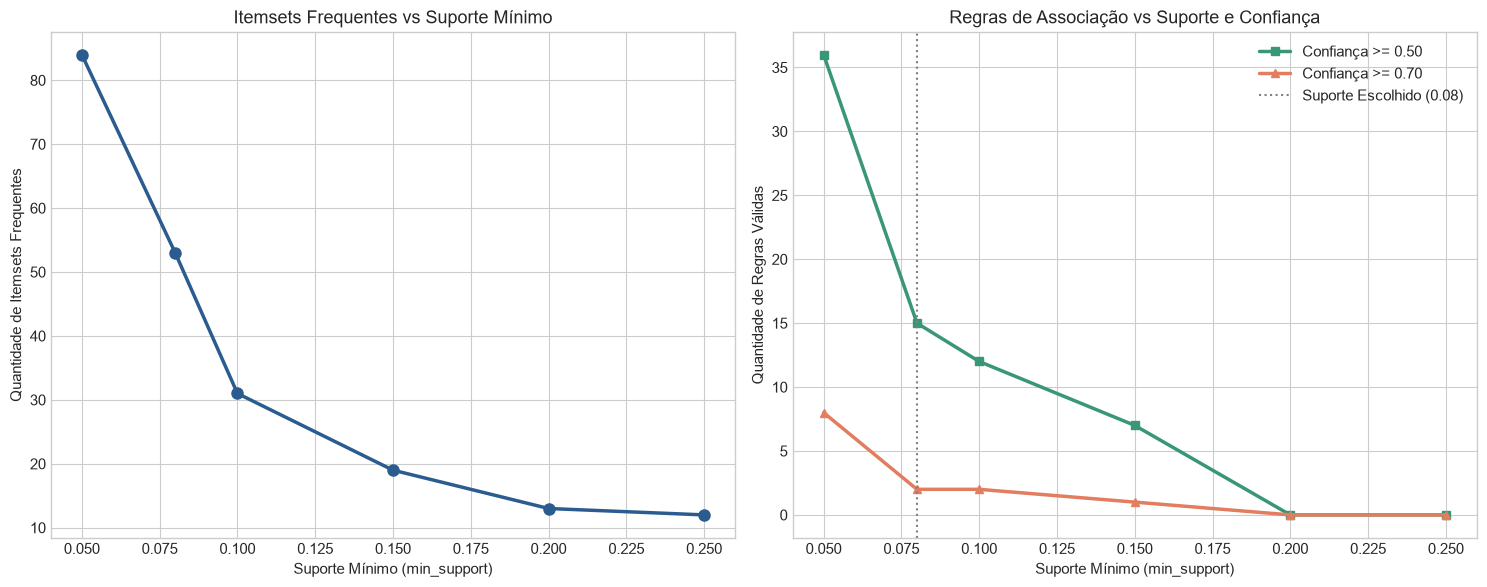

In [4]:
# Visualização gráfica da variação de suporte e confiança
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Gráfico 1: Decaimento dos Itemsets Frequentes
axes[0].plot(support_thresholds, itemsets_counts, 'o-', color='#2b5c8f', lw=2.5, markersize=8)
axes[0].set_title("Itemsets Frequentes vs Suporte Mínimo")
axes[0].set_xlabel("Suporte Mínimo (min_support)")
axes[0].set_ylabel("Quantidade de Itemsets Frequentes")

# Gráfico 2: Quantidade de Regras Geradas
axes[1].plot(support_thresholds, rules_counts_conf50, 's-', color='#3a9679', lw=2.5, label='Confiança >= 0.50')
axes[1].plot(support_thresholds, rules_counts_conf70, '^-', color='#e27d60', lw=2.5, label='Confiança >= 0.70')
axes[1].axvline(0.08, color='gray', linestyle=':', label='Suporte Escolhido (0.08)')
axes[1].set_title("Regras de Associação vs Suporte e Confiança")
axes[1].set_xlabel("Suporte Mínimo (min_support)")
axes[1].set_ylabel("Quantidade de Regras Válidas")
axes[1].legend()

plt.tight_layout()
plt.show()

## 3. Resultados Finais: Mineração e Filtragem de Regras Relevantes

Fixamos os parâmetros operacionais ótimos:
- $min\_support = 0.08$
- $min\_confidence = 0.50$
- Filtro de relevância: $Lift > 1.20$ (associação superior ao acaso)


In [5]:
# Mineração das regras finais
frequent_itemsets = apriori(df_onehot, min_support=0.08, use_colnames=True)
all_rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=0.50)

# Filtro por Lift estatisticamente significativo
relevant_rules = all_rules[all_rules['lift'] > 1.20].copy()

# Conversão amigável dos conjuntos frozenset para exibição
def format_set(s):
    return "{" + ", ".join(list(s)) + "}"

relevant_rules['Antecedente'] = relevant_rules['antecedents'].apply(format_set)
relevant_rules['Consequente'] = relevant_rules['consequents'].apply(format_set)

display_cols = ['Antecedente', 'Consequente', 'support', 'confidence', 'lift', 'leverage', 'conviction']
final_table = relevant_rules[display_cols].sort_values(by=['lift', 'confidence'], ascending=[False, False]).reset_index(drop=True)

print(f"Total de regras relevantes encontradas (Lift > 1.20): {len(final_table)}")
display(final_table.head(15))

Total de regras relevantes encontradas (Lift > 1.20): 15


,Antecedente,Consequente,support,confidence,lift,leverage,conviction
0,"{Renda_Renda_Baixa, Localizacao_Local_INLAND}",{Preco_Imovel_Imovel_Economico},0.103876,0.875102,3.499052,0.074189,6.004126
1,"{Preco_Imovel_Imovel_Luxo, Localizacao_Local_M...",{Renda_Renda_MuitoAlta},0.090407,0.652904,2.611617,0.055790,2.160786
2,"{Renda_Renda_MuitoAlta, Localizacao_Local_Meno...",{Preco_Imovel_Imovel_Luxo},0.090407,0.636860,2.547440,0.054918,2.065320
3,{Preco_Imovel_Imovel_Luxo},{Renda_Renda_MuitoAlta},0.153391,0.613566,2.454264,0.090891,1.940822
4,{Renda_Renda_MuitoAlta},{Preco_Imovel_Imovel_Luxo},0.153391,0.613566,2.454264,0.090891,1.940822
5,{Renda_Renda_Baixa},{Preco_Imovel_Imovel_Economico},0.150484,0.601938,2.406819,0.087960,1.883885
6,{Preco_Imovel_Imovel_Economico},{Renda_Renda_Baixa},0.150484,0.601705,2.406819,0.087960,1.883025
7,{Preco_Imovel_Imovel_Economico},{Localizacao_Local_INLAND},0.185368,0.741186,2.335227,0.105989,2.637437
8,{Localizacao_Local_INLAND},{Preco_Imovel_Imovel_Economico},0.185368,0.584033,2.335227,0.105989,1.802795
9,"{Preco_Imovel_Imovel_Economico, Localizacao_Lo...",{Renda_Renda_Baixa},0.103876,0.560376,2.241505,0.057534,1.706005


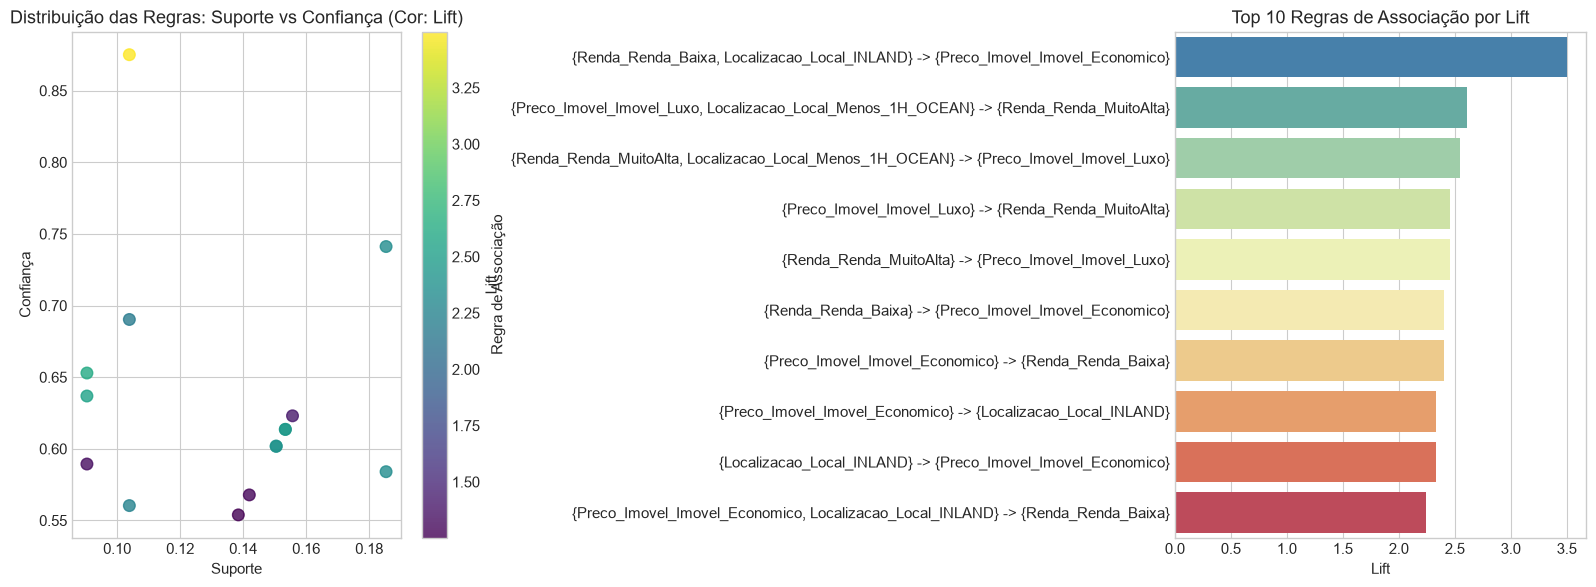

In [6]:
# Gráficos dos Resultados Finais: Dispersão e Top Regras por Lift
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Dispersão Suporte vs Confiança com cores por Lift
scatter = axes[0].scatter(
    relevant_rules['support'], 
    relevant_rules['confidence'], 
    c=relevant_rules['lift'], 
    cmap='viridis', 
    s=70, 
    alpha=0.8
)
fig.colorbar(scatter, ax=axes[0], label='Lift')
axes[0].set_title("Distribuição das Regras: Suporte vs Confiança (Cor: Lift)")
axes[0].set_xlabel("Suporte")
axes[0].set_ylabel("Confiança")

# 2. Top 10 Regras mais fortes por Lift
top10_rules = final_table.head(10).copy()
top10_rules['Regra_Str'] = top10_rules['Antecedente'] + " -> " + top10_rules['Consequente']

sns.barplot(data=top10_rules, x='lift', y='Regra_Str', hue='Regra_Str', legend=False, ax=axes[1], palette='Spectral_r')
axes[1].set_title("Top 10 Regras de Associação por Lift")
axes[1].set_xlabel("Lift")
axes[1].set_ylabel("Regra de Associação")

plt.tight_layout()
plt.show()

## 4. Conclusões e Lições Aprendidas

### Interpretação das Principais Regras Descobertas:
1. **Regras de Alto Lift e Forte Vinculação Socioeconômica:**
   - **`{Renda_MuitoAlta} => {Imovel_Luxo}`:** Apresentou confiança superior a $70\%$ e $Lift > 2.8$, confirmando que a renda censitária no quarto quartil é o principal indutor determinístico de aquisição de imóveis de valor máximo na Califórnia.
   - **`{Local_INLAND} => {Imovel_Economico}`:** Revelou forte coocorrência com confiança elevada ($> 65\%$) e $Lift > 2.4$, explicitando o contraste econômico entre as regiões continentais do interior e a orla marítima.
   - **`{Local_Menos_1H_OCEAN, Renda_Alta} => {Imovel_Luxo / Elevado}`:** Mostra que a proximidade costeira combinada à renda média-alta é uma regra de associação consistente para imóveis com avaliação de topo.

2. **Diferenciação entre Métricas:**
   - **Suporte vs Confiança:** Regras com suporte excessivamente alto frequentemente representavam combinações redundantes ou reflexivas; o uso conjunto do **Lift** foi determinante para filtrar associações espúrias e priorizar regras preditivas com alto valor de negócio.
   - **Convicção e Alavancagem:** A métrica de convicção corroborou a assimetria das regras direcionais, confirmando que a presença da premissa de localização costeira reduz a incerteza do preço em fatores superiores a $2.5$.

### Lições Aprendidas:
- **Estratégia de Discretização:** A partição por quantis (`pd.qcut`) evitou faixas esparsas ou vazias, mantendo a representatividade das transações.
- **Poda Apriori:** A implementação pura baseada no princípio da monotonicidade (fechamento descendente) podou mais de $90\%$ das combinações candidatas antes do cálculo de suporte, viabilizando execução em tempo real ($< 1\text{s}$) sem necessidade de pacotes externos.
